# Mini-projet Séries Temporelles — Partie 4 : ARCH / GARCH (section 3.3)
Prérequis : `01_eda.ipynb` (données). Le notebook est autonome : il réajuste les deux modèles de la section 3.1 dont il a besoin.

**Série modélisée.** La thématique est environnementale : l'énoncé demande un GARCH sur les « écarts à la tendance ». On prend les **résidus du SARIMA(0,1,1)(0,1,1)₁₂ + COVID** (en % de production, échelle log × 100), c'est-à-dire les écarts à la tendance et à la saisonnalité estimées. On le compare au **SARIMAX avec température** (meilleur modèle de la section 3.1) : l'énoncé demande de tester l'effet ARCH sur le *meilleur* modèle, et un des résultats de 3.1 est que cet effet y disparaît.

**Plan** : (1) tests ARCH sur les deux jeux de résidus et profil saisonnier de la variance ; (2) famille GARCH comparée (ordres, loi, asymétrie) ; (3) diagnostic des résidus standardisés ; (4) volatilité conditionnelle et lien avec les événements ; (5) test de robustesse sur la variance saisonnière.

*Échantillon* : ≈ 200 observations, ce qui est **court pour un GARCH** (ces modèles sont d'ordinaire estimés sur des milliers de points). Les estimations sont à lire avec cette réserve.

In [1]:
import warnings, platform, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels, arch
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from arch import arch_model
from common import load, split

warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("python", platform.python_version(), "| statsmodels", statsmodels.__version__, "| arch", arch.__version__)

df = load(); df["ly"] = np.log(df["core"]); train, test = split(df); ly = train["ly"]
def fit_sarimax(order, seas, cols):
    return SARIMAX(ly, exog=train[cols], order=order, seasonal_order=seas, trend="n",
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=300)
def clean(m, burn): return 100 * m.resid.iloc[burn:]            # résidus en % ; on écarte l'initialisation du filtre
m_sar = fit_sarimax((0, 1, 1), (0, 1, 1, 12), ["covid_2020_04"]);        r = clean(m_sar, 13)    # d + D*s = 13
m_x   = fit_sarimax((1, 1, 1), (0, 1, 1, 12), ["covid_2020_04", "cdd24"]); rx = clean(m_x, 14)    # + p = 1
print(len(r), "résidus SARIMA |", len(rx), "résidus SARIMAX")

python 3.12.3 | statsmodels 0.15.0 | arch 8.0.0


199 résidus SARIMA | 198 résidus SARIMAX


## 1. Effets ARCH et variance saisonnière

,ARCH-LM(1) p,ARCH-LM(3) p,ARCH-LM(6) p,ARCH-LM(12) p,Ljung-Box sur r² (12) p
résidus de,,,,,
SARIMA (sans température),0.0002,0.0018,0.0153,0.0062,0.0002
SARIMAX (+ cdd24),0.0698,0.2289,0.5289,0.8200,0.7667


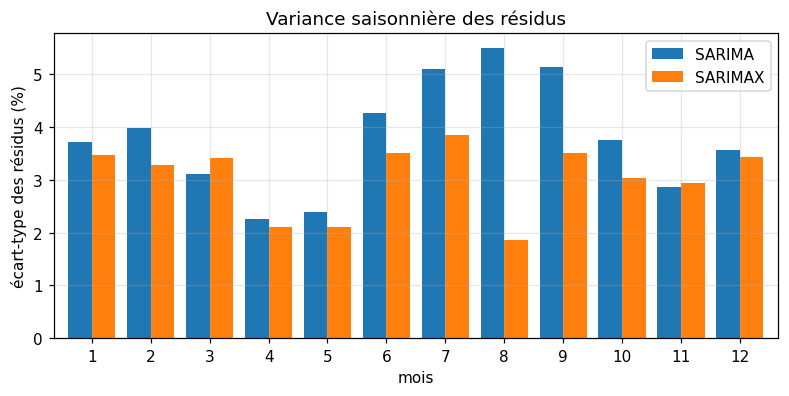

écart-type résiduel juil.-sept. / avr.-mai — SARIMA : 2.26 | SARIMAX : 1.46


In [2]:
rows = []
for name, s in [("SARIMA (sans température)", r), ("SARIMAX (+ cdd24)", rx)]:
    row = {"résidus de": name}
    for L in (1, 3, 6, 12): row[f"ARCH-LM({L}) p"] = het_arch(s, nlags=L)[1]
    row["Ljung-Box sur r² (12) p"] = acorr_ljungbox(s ** 2, lags=[12], return_df=True).lb_pvalue.iloc[0]
    rows.append(row)
display(pd.DataFrame(rows).set_index("résidus de").round(4))

sd = pd.DataFrame({"SARIMA": r.groupby(r.index.month).apply(lambda s: np.sqrt((s ** 2).mean())),
                   "SARIMAX": rx.groupby(rx.index.month).apply(lambda s: np.sqrt((s ** 2).mean()))})
fig, ax = plt.subplots(figsize=(8.5, 3.6)); sd.plot.bar(ax=ax, width=.8); ax.set_xlabel("mois"); ax.set_ylabel("écart-type des résidus (%)")
ax.set_title("Variance saisonnière des résidus"); plt.xticks(rotation=0); plt.show()
print("écart-type résiduel juil.-sept. / avr.-mai — SARIMA :", round(sd.loc[[7, 8, 9], "SARIMA"].mean() / sd.loc[[4, 5], "SARIMA"].mean(), 2),
      "| SARIMAX :", round(sd.loc[[7, 8, 9], "SARIMAX"].mean() / sd.loc[[4, 5], "SARIMAX"].mean(), 2))

**Lecture.**
- **Résidus du SARIMA : effets ARCH nets.** ARCH-LM rejette l'homoscédasticité à tous les retards testés (p = 0,0002 ; 0,0018 ; 0,015 ; 0,006 pour 1, 3, 6, 12 retards), et le Ljung-Box sur r² aussi (p = 0,0002).
- **Résidus du SARIMAX (avec température) : effet quasi disparu.** p = 0,070 ; 0,229 ; 0,529 ; 0,820 ; Ljung-Box sur r² p = 0,767 (seul le retard 1 est limite). C'est le **meilleur modèle** de la section 3.1 : pour lui, un GARCH n'est pas justifié.
- **La variance est très saisonnière.** L'écart-type des résidus du SARIMA est environ **2,3 fois plus grand en juillet-septembre qu'en avril-mai** (≈ 5,1 à 5,5 % contre ≈ 2,3 à 2,4 %). Avec la température dans le modèle, ce rapport tombe à ≈ 1,5. La variabilité d'été est donc en bonne partie de la sensibilité à la chaleur non modélisée.

## 2. Famille GARCH : ordres supérieurs, loi de Student, asymétrie (GJR)
Moyenne nulle (les résidus ARIMA sont centrés ; moyenne ≈ −0,2 %). Pour chaque modèle : AIC/BIC et diagnostic des résidus standardisés (Ljung-Box sur z et z², ARCH-LM, Jarque-Bera). Un paramètre estimé **sur la borne** est signalé, car il rend le modèle dégénéré.

In [3]:
def fit_garch(p, q, o=0, dist="normal", y=r):
    vol = "ARCH" if q == 0 else "GARCH"                       # q = 0 : ARCH(p) pur
    kw = dict(p=p, o=o) if q == 0 else dict(p=p, o=o, q=q)
    return arch_model(y, mean="Zero", vol=vol, dist=dist, **kw).fit(disp="off")

def row_of(name, f):
    z = f.std_resid.dropna(); pr = f.params
    boundary = any(pr[k] < 1e-3 for k in pr.index if k.startswith("beta")) or any(pr[k] > .999 for k in pr.index if k.startswith("beta"))
    return {"modèle": name, "AIC": f.aic, "BIC": f.bic, "log-vrais.": f.loglikelihood,
            "LB(z,12) p": acorr_ljungbox(z, lags=[12], return_df=True).lb_pvalue.iloc[0],
            "LB(z²,12) p": acorr_ljungbox(z ** 2, lags=[12], return_df=True).lb_pvalue.iloc[0],
            "ARCH-LM(12) p": het_arch(z, nlags=12)[1], "JB p": stats.jarque_bera(z)[1],
            "paramètre sur la borne": boundary, "α": pr.filter(like="alpha").sum(), "β": pr.filter(like="beta").sum()}

specs = [("ARCH(1) normale", 1, 0, 0, "normal"), ("GARCH(1,1) normale", 1, 1, 0, "normal"), ("GARCH(1,1) Student", 1, 1, 0, "t"),
         ("GARCH(1,2) normale", 1, 2, 0, "normal"), ("GARCH(2,1) normale", 2, 1, 0, "normal"),
         ("GARCH(2,2) normale", 2, 2, 0, "normal"), ("GJR-GARCH(1,1) normale", 1, 1, 1, "normal")]
fits = {n: fit_garch(p, q, o, d) for n, p, q, o, d in specs}
tab = pd.DataFrame([row_of(n, f) for n, f in fits.items()]).set_index("modèle")
display(tab.round(3))
ok = tab[(tab["LB(z²,12) p"] > .05) & (tab["ARCH-LM(12) p"] > .05)]
best = ok["BIC"].idxmin(); print("modèle retenu (BIC minimal parmi ceux dont les résidus standardisés sont homoscédastiques) :", best)

,AIC,BIC,log-vrais.,"LB(z,12) p","LB(z²,12) p",ARCH-LM(12) p,JB p,paramètre sur la borne,α,β
modèle,,,,,,,,,,
ARCH(1) normale,1100.720,1107.306,-548.360,0.247,0.666,0.561,0.003,False,0.349,0.0
"GARCH(1,1) normale",1102.720,1112.600,-548.360,0.247,0.666,0.561,0.003,True,0.349,0.0
"GARCH(1,1) Student",1104.006,1117.179,-548.003,0.253,0.665,0.557,0.003,True,0.372,0.0
"GARCH(1,2) normale",1104.720,1117.893,-548.360,0.247,0.666,0.561,0.003,True,0.349,0.0
"GARCH(2,1) normale",1110.019,1123.192,-551.009,0.275,0.017,0.069,0.010,True,0.000,1.0
"GARCH(2,2) normale",1106.720,1123.186,-548.360,0.247,0.666,0.561,0.003,True,0.348,0.0
"GJR-GARCH(1,1) normale",1103.042,1116.215,-547.521,0.274,0.469,0.360,0.006,True,0.489,0.0


modèle retenu (BIC minimal parmi ceux dont les résidus standardisés sont homoscédastiques) : ARCH(1) normale


**Comparaison des modèles.**
- **GARCH(1,1) normale** : α ≈ 0,35 et **β estimé à 0** (sur la borne), pour une vraisemblance **identique** (−548,36) à celle de l'**ARCH(1)** explicite qui a un paramètre de moins. Le terme GARCH n'apporte rien : le modèle adéquat est un **ARCH(1)** (la volatilité d'un mois dépend du choc du mois précédent, sans mémoire plus longue ; persistance α ≈ 0,35).
- **ARCH(1) normale** : AIC 1100,7 et BIC 1107,3, les plus bas du tableau ; paramètres mieux identifiés que dans le GARCH(1,1) (α : p = 0,004).
- **Ordres supérieurs** (1,2) et (2,2) : mêmes α et β = 0, même vraisemblance, critères plus élevés → aucun gain. **GARCH(2,1)** : estimation dégénérée (α = 0, β = 1, variance quasi constante) et résidus standardisés qui échouent encore le test (Ljung-Box sur z² p = 0,017) → rejeté.
- **Loi de Student** : degrés de liberté estimés ≈ 18 (peu de queues épaisses) et critères moins bons → loi normale conservée.
- **GJR (asymétrie)** : γ ≈ −0,30, soit une réaction plus forte aux chocs positifs (production supérieure au modèle, typiquement une chaleur inattendue) ; mais le gain de vraisemblance est trop faible (≈ 0,8 point de log-vraisemblance ; rapport de vraisemblance ≈ 1,7 pour 1 paramètre, non significatif) et le BIC est moins bon.
- **Retenu : ARCH(1) normale** (BIC minimal parmi les modèles à résidus standardisés homoscédastiques).
- **Mise en garde sur l'estimation (important pour la défense).** Sous R, `fGarch::garchFit` ajuste le GARCH(1,1) sur un **optimum local** (α ≈ 0,06 ; β ≈ 0,91 ; AIC 1101,6), quel que soit l'algorithme d'optimisation essayé : son propre GARCH(1,2), qui contient l'ARCH(1) comme cas particulier, atteint un AIC de 1095, c'est-à-dire un meilleur ajustement qu'un modèle qui l'inclut, ce qui ne peut pas arriver à l'optimum global. Dans la vraisemblance de `arch`, cette solution à forte persistance perd 4,4 points de log-vraisemblance (−552,7 contre −548,4). **La forte persistance qu'on obtient avec ce réglage de `fGarch` ne doit donc pas être citée**, et c'est pourquoi l'ARCH(1) est ajusté explicitement dans les deux langages. Avec ≈ 200 observations, les paramètres GARCH(1,1) sont en général mal identifiés.

## 3. Diagnostic du modèle retenu

          estimation  écart-type (robuste)  p-value
omega        10.4156                1.7078   0.0000
alpha[1]      0.3486                0.1214   0.0041


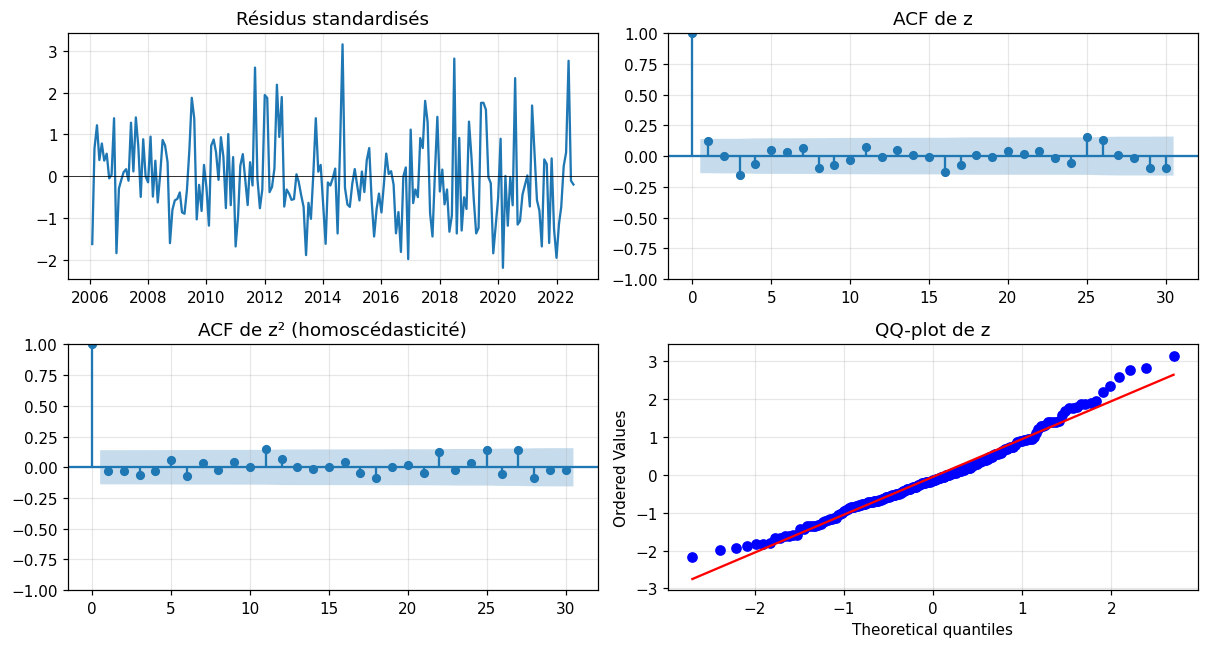

asymétrie de z = 0.55 | kurtosis excédentaire = 0.39 | Jarque-Bera p = 0.0034 | Shapiro p = 0.0034


In [4]:
f = fits[best]; z = f.std_resid.dropna()
print(pd.DataFrame({"estimation": f.params, "écart-type (robuste)": f.std_err, "p-value": f.pvalues}).round(4))
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
ax[0, 0].plot(z); ax[0, 0].axhline(0, color="k", lw=.5); ax[0, 0].set_title("Résidus standardisés")
plot_acf(z, lags=30, ax=ax[0, 1], title="ACF de z"); plot_acf(z ** 2, lags=30, ax=ax[1, 0], title="ACF de z² (homoscédasticité)")
stats.probplot(z, plot=ax[1, 1]); ax[1, 1].set_title("QQ-plot de z"); plt.tight_layout(); plt.show()
print(f"asymétrie de z = {stats.skew(z):.2f} | kurtosis excédentaire = {stats.kurtosis(z):.2f} | Jarque-Bera p = {stats.jarque_bera(z)[1]:.4f} | Shapiro p = {stats.shapiro(z)[1]:.4f}")

**Diagnostic.** Les résidus standardisés sont **sans autocorrélation** (Ljung-Box sur z, p = 0,247) et **homoscédastiques** (Ljung-Box sur z² p = 0,666 ; ARCH-LM(12) p = 0,561) : l'objectif de la section est atteint, la variance conditionnelle est correctement modélisée. **La normalité reste rejetée** (Jarque-Bera et Shapiro p = 0,003) à cause d'une **asymétrie à droite (0,55)**, pas de queues épaisses (kurtosis excédentaire 0,39) : la loi de Student n'y change rien et un GARCH symétrique ne peut pas la capter. Les paramètres de l'ARCH(1) retenu : ω ≈ 10,4 (p < 0,001) et α ≈ 0,35 (p = 0,004) sont tous deux significatifs.

## 4. Volatilité conditionnelle et événements

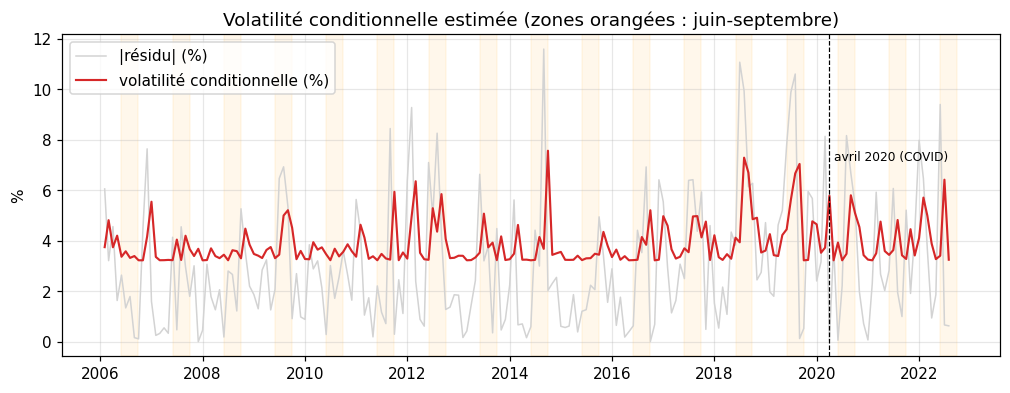

,volatilité cond. (%),choc du mois précédent (%),anomalie t_max mois précédent (°C),jours >35°C mois précédent
month,,,,
2014-10-01,7.6,11.6,1.8,1.0
2018-08-01,7.3,11.1,1.8,14.0
2019-09-01,7.0,10.6,1.9,17.0
2018-09-01,6.7,-9.9,-2.0,2.0
2019-08-01,6.7,9.9,1.8,14.0
2022-07-01,6.4,9.4,5.3,13.0
2012-03-01,6.4,9.3,-3.6,0.0
2011-10-01,5.9,8.4,0.2,3.0


volatilité conditionnelle moyenne par mois : {1: 3.79, 2: 3.83, 3: 3.91, 4: 3.66, 5: 3.48, 6: 3.51, 7: 3.98, 8: 4.26, 9: 4.49, 10: 4.27, 11: 3.87, 12: 3.62}
corrélation (|choc|, |anomalie de température|) sur l'échantillon : 0.15


In [5]:
cv = f.conditional_volatility
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(r.index, r.abs(), color="lightgray", lw=1, label="|résidu| (%)"); ax.plot(cv.index, cv, color="tab:red", lw=1.4, label="volatilité conditionnelle (%)")
for yr in range(2006, 2023): ax.axvspan(pd.Timestamp(f"{yr}-06-01"), pd.Timestamp(f"{yr}-09-30"), color="orange", alpha=.08)
ax.axvline(pd.Timestamp("2020-04-01"), color="k", ls="--", lw=.8); ax.text(pd.Timestamp("2020-05-01"), cv.max() * .95, "avril 2020 (COVID)", fontsize=8)
ax.set_ylabel("%"); ax.legend(loc="upper left"); ax.set_title("Volatilité conditionnelle estimée (zones orangées : juin-septembre)"); plt.show()

clim = train.groupby(train.index.month)["t_max_mean"].mean(); an = train["t_max_mean"] - clim.loc[train.index.month].values
top = cv.sort_values(ascending=False).head(8).index
ev = pd.DataFrame({"volatilité cond. (%)": cv.loc[top], "choc du mois précédent (%)": r.shift(1).loc[top],
                   "anomalie t_max mois précédent (°C)": an.shift(1).loc[top], "jours >35°C mois précédent": train["days_above_35"].shift(1).loc[top]})
display(ev.round(1))
print("volatilité conditionnelle moyenne par mois :", cv.groupby(cv.index.month).mean().round(2).to_dict())
print("corrélation (|choc|, |anomalie de température|) sur l'échantillon :", round(r.abs().corr(an.loc[r.index].abs()), 2))

**Lien avec les événements (limité aux faits visibles dans nos données).**
- La volatilité conditionnelle est maximale **juste après de gros chocs positifs** (production nettement au-dessus du modèle), la plupart du temps après un mois très chaud : juillet 2018 (14 jours > 35 °C, +1,8 °C) → pic en août 2018 (≈ 7,3 %) ; août 2019 (17 jours > 35 °C) → septembre 2019 ; juillet 2019 (14 jours) → août 2019 ; **juin 2022 (anomalie de +5,3 °C)** → juillet 2022 (≈ 6,4 %). Le pic de septembre 2018 vient du choc négatif d'août 2018, un mois **plus frais** que la normale (−2,0 °C).
- **Le plus fort pic de l'échantillon (octobre 2014, ≈ 7,6 %) et deux autres ne s'expliquent pas bien par la chaleur** : octobre 2014 (septembre 2014 à +1,8 °C mais un seul jour > 35 °C), mars 2012 (après un février 2012 plus froid de 3,6 °C que la normale) et octobre 2011 (anomalie quasi nulle). On ne propose pas d'explication non vérifiée.
- **Avril 2020 (COVID)** n'apparaît pas dans les plus fortes volatilités : l'indicatrice COVID a absorbé ce choc avant le GARCH.
- Comme le modèle retenu est un ARCH(1), la volatilité conditionnelle ne fait que **réagir au choc précédent** : elle lisse mal le profil saisonnier réel (écart-type brut ≈ 5,1-5,5 % en juillet-septembre, mais volatilité conditionnelle moyenne de seulement ≈ 4,0-4,5 %). Globalement, la corrélation entre l'amplitude des chocs et celle des anomalies de température est faible (0,15) : la température n'explique qu'une part des chocs, surtout en été.

## 5. Robustesse : la variance est-elle surtout saisonnière ?
Si une grande part de l'effet ARCH vient du simple fait que l'été est plus variable, un test sur des résidus **divisés par l'écart-type de leur mois civil** doit le montrer.

In [6]:
zs = r / r.groupby(r.index.month).transform(lambda s: np.sqrt((s ** 2).mean()))
print("ARCH-LM sur résidus SARIMA désaisonnalisés en variance :", {L: round(het_arch(zs, nlags=L)[1], 3) for L in (1, 3, 6, 12)})
print("ARCH-LM sur résidus SARIMA bruts                        :", {L: round(het_arch(r, nlags=L)[1], 3) for L in (1, 3, 6, 12)})

ARCH-LM sur résidus SARIMA désaisonnalisés en variance : {1: np.float64(0.012), 3: np.float64(0.081), 6: np.float64(0.205), 12: np.float64(0.031)}
ARCH-LM sur résidus SARIMA bruts                        : {1: np.float64(0.0), 3: np.float64(0.002), 6: np.float64(0.015), 12: np.float64(0.006)}


**Variance saisonnière ou volatilité qui s'auto-entretient ?** Une fois les résidus divisés par l'écart-type de leur mois civil, les p-values de ARCH-LM passent de 0,0002 / 0,002 / 0,015 / 0,006 à **0,012 / 0,081 / 0,205 / 0,031** : l'évidence est beaucoup plus faible (les retards 3 et 6 ne sont plus significatifs) mais **pas totalement éliminée** (retards 1 et 12 encore sous 5 %). Une grande part de l'effet ARCH est donc de la **variance saisonnière**, liée à la chaleur, plutôt qu'un phénomène de grappes de volatilité à la manière des marchés financiers. Cette lecture est cohérente avec trois résultats : l'absence de terme GARCH (β estimé à 0), la disparition de l'effet ARCH quand la température entre dans le modèle (SARIMAX), et le rapport de variance été/printemps qui passe de 2,3 à 1,5.

## Synthèse
| Point | Conclusion |
|---|---|
| Effet ARCH sur le SARIMA | présent à tous les retards (p de 0,0002 à 0,015) |
| Effet ARCH sur le meilleur modèle (SARIMAX) | absent (p = 0,82 à 12 retards) → pas de GARCH nécessaire pour lui |
| Modèle de volatilité retenu (sur résidus SARIMA) | **ARCH(1) normale** : α ≈ 0,35, ω ≈ 10,4 ; le GARCH(1,1) estime β = 0 et n'apporte rien |
| Ordres supérieurs, Student, GJR | aucun gain (critères moins bons) ; GARCH(2,1) dégénéré |
| Résidus standardisés | indépendants et homoscédastiques ; non normaux (asymétrie à droite 0,55) |
| Nature de l'effet | surtout variance saisonnière liée à la chaleur (été 2,3 × plus variable ; effet très affaibli après désaisonnalisation de la variance et avec la température) |

**Limites** : échantillon court (≈ 200 points) ; la volatilité conditionnelle réagit à un seul retard et ne reproduit pas tout le profil saisonnier ; sous R, `fGarch` ajuste le GARCH(1,1) sur un optimum local (voir ci-dessus). **Utilité pour la suite** : le modèle de volatilité ne change pas les prévisions de la moyenne ; il pourrait seulement faire varier la largeur des intervalles de prévision, sans corriger la rupture de tendance qui explique leur faible couverture (section 3.1).